# PepsiCo 1-Day 99% Value at Risk

# Author: Jaime Corzo Galdó

The objective of this analysis is to estimate the 1-day 99% Value at Risk (VaR) of a $100,000 investment in PepsiCo (PEP).

Two methods are used:

1. Historical VaR
2. Parametric VaR using a Student-t distribution

The analysis uses approximately 40 years of daily PepsiCo stock price data from Yahoo Finance.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from scipy import stats

## 1. Download PepsiCo Data

Daily PepsiCo prices are downloaded from Yahoo Finance.

Adjusted closing prices are used because they account for events such as stock splits and dividends. The sample covers approximately 40 years.

In [2]:
ticker = "PEP"

start_date = "1986-10-20"
end_date = "2026-10-21"

data = yf.download(
    ticker,
    start=start_date,
    end=end_date,
    auto_adjust=False,
    progress=False
)

pep = data["Adj Close"].squeeze().dropna()

print("First observation:", pep.index.min().date())
print("Last observation:", pep.index.max().date())
print("Number of price observations:", len(pep))

pep.head()

First observation: 1986-10-20
Last observation: 2026-10-20
Number of price observations: 10077


Date
1986-10-20    1.685737
1986-10-21    1.662645
1986-10-22    1.678041
1986-10-23    1.716528
1986-10-24    1.670342
Name: PEP, dtype: float64

## 2. Calculate Daily Returns

VaR is calculated using returns rather than stock prices.

The simple daily return is

$$r_t = \frac{P_t-P_{t-1}}{P_{t-1}}$$

where $$P_t$$ is the adjusted closing price on day $$t$$.

Each observation therefore represents the percentage gain or loss in PepsiCo stock over one trading day.

In [3]:
returns = pep.pct_change().dropna()

print("Number of daily returns:", len(returns))
print()
print(returns.describe())

Number of daily returns: 10076

count    10076.000000
mean         0.000545
std          0.014874
min         -0.119313
25%         -0.006720
50%          0.000000
75%          0.007762
max          0.161435
Name: PEP, dtype: float64


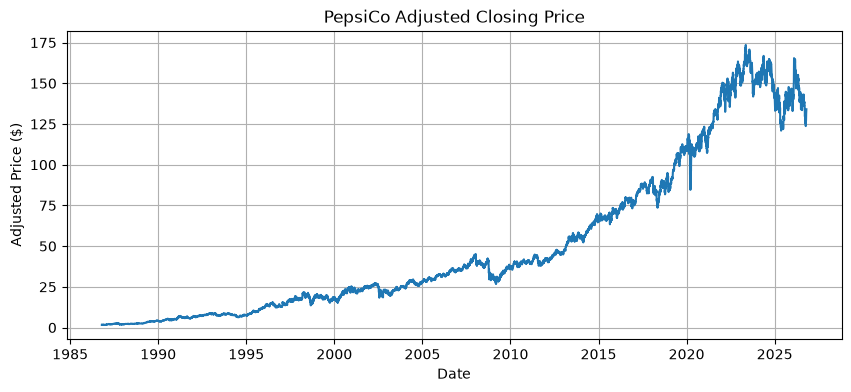

In [4]:
plt.figure(figsize=(10, 4))
plt.plot(pep)
plt.title("PepsiCo Adjusted Closing Price")
plt.xlabel("Date")
plt.ylabel("Adjusted Price ($)")
plt.grid(True)
plt.show()

## 3. Historical 1-Day 99% VaR

The historical method does not assume a particular probability distribution.

For a 99% VaR, the relevant point is the 1st percentile of the historical daily return distribution. This is because only 1% of historical returns are worse than this threshold.

The historical return-at-risk is therefore

$$q_{0.01} = \text{1st percentile of daily returns}$$

and the dollar VaR for a $100,000 position is

$$VaR_{99\%} = -100,000 \times q_{0.01}.$$

The negative sign converts the negative return into a positive dollar loss.

In [5]:
portfolio_value = 100000
confidence_level = 0.99

historical_quantile = returns.quantile(1 - confidence_level)

historical_var = -portfolio_value * historical_quantile

print(f"1% historical return quantile: {historical_quantile:.4%}")
print(f"Historical 1-day 99% VaR: ${historical_var:,.2f}")

1% historical return quantile: -3.8481%
Historical 1-day 99% VaR: $3,848.07


## 4. Distribution of PepsiCo Returns

A parametric VaR requires us to choose a probability distribution for daily returns.

A Normal distribution is a common starting point, but financial returns can have heavier tails than the Normal distribution. This means that very large positive or negative returns may occur more frequently than the Normal model predicts.

The histogram and Normal Q-Q plot below are used to examine whether the Normal distribution is a reasonable approximation.

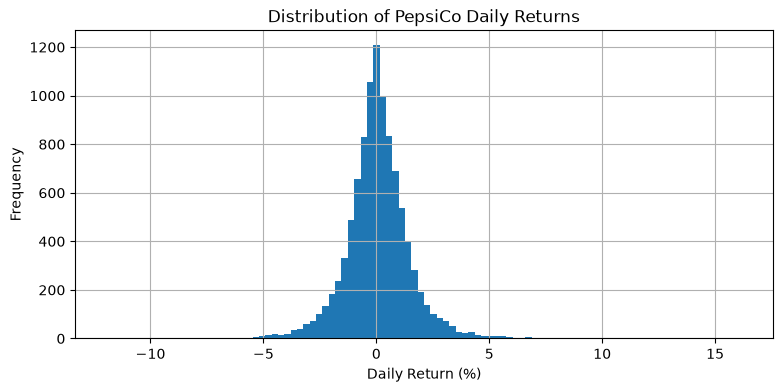

In [6]:
plt.figure(figsize=(9, 4))

plt.hist(returns * 100, bins=100)

plt.title("Distribution of PepsiCo Daily Returns")
plt.xlabel("Daily Return (%)")
plt.ylabel("Frequency")
plt.grid(True)

plt.show()

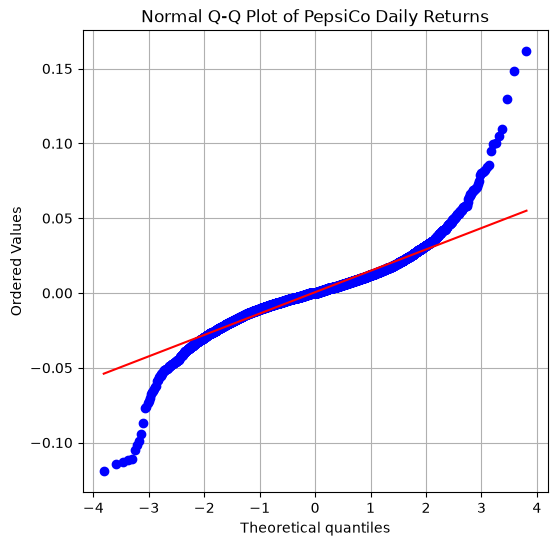

In [7]:
plt.figure(figsize=(6, 6))

stats.probplot(returns, dist="norm", plot=plt)

plt.title("Normal Q-Q Plot of PepsiCo Daily Returns")
plt.grid(True)

plt.show()

In [8]:
excess_kurtosis = stats.kurtosis(returns)

print(f"Excess kurtosis: {excess_kurtosis:.2f}")

Excess kurtosis: 8.86


## 5. Parametric VaR Using a Student-t Distribution

The Q-Q plot shows departures from Normality in the tails, and the return distribution exhibits excess kurtosis. Therefore, a Student-t distribution is used for the parametric VaR calculation.

The Student-t distribution is similar to the Normal distribution around its center but allows for heavier tails. This makes it useful for financial returns where extreme observations occur more frequently than predicted by a Normal distribution.

The parameters of the Student-t distribution are estimated from the historical PepsiCo daily returns. The 1st percentile of the fitted distribution is then used to calculate the 1-day 99% VaR.

In [9]:
df, loc, scale = stats.t.fit(returns)

print(f"Degrees of freedom: {df:.2f}")
print(f"Location parameter: {loc:.6f}")
print(f"Scale parameter: {scale:.6f}")

Degrees of freedom: 3.25
Location parameter: 0.000384
Scale parameter: 0.009637


In [10]:
student_t_quantile = stats.t.ppf(
    1 - confidence_level,
    df=df,
    loc=loc,
    scale=scale
)

student_t_var = -portfolio_value * student_t_quantile

print(f"1% Student-t return quantile: {student_t_quantile:.4%}")
print(f"Student-t 1-day 99% VaR: ${student_t_var:,.2f}")

1% Student-t return quantile: -4.0757%
Student-t 1-day 99% VaR: $4,075.74


## 6. Comparison of VaR Estimates

The two methods estimate the same risk quantity but use different approaches.

The historical method uses the empirical distribution of observed PepsiCo returns and therefore makes no explicit distributional assumption.

The Student-t method fits a parametric distribution to the return data. The Student-t distribution was selected because the return data display heavier tails than would be expected under a Normal distribution.

In [11]:
results = pd.DataFrame({
    "Method": [
        "Historical",
        "Student-t"
    ],
    "1-Day 99% VaR ($)": [
        historical_var,
        student_t_var
    ]
})

results

,Method,1-Day 99% VaR ($)
0,Historical,3848.072929
1,Student-t,4075.739166


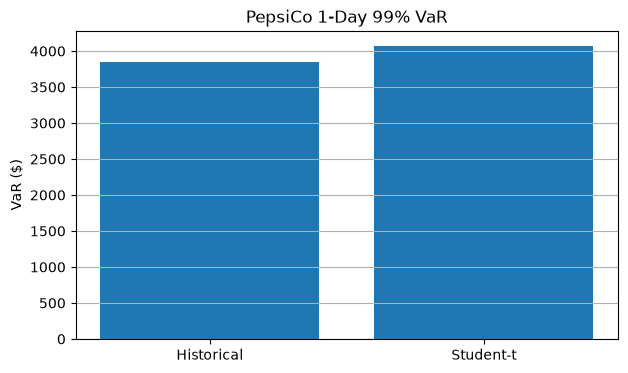

In [12]:
plt.figure(figsize=(7, 4))

plt.bar(
    ["Historical", "Student-t"],
    [historical_var, student_t_var]
)

plt.title("PepsiCo 1-Day 99% VaR")
plt.ylabel("VaR ($)")
plt.grid(axis="y")

plt.show()

## 7. Interpretation

The historical 1-day 99% VaR is approximately **$3,848**, while the Student-t parametric VaR is approximately **$4,076**.

The historical result means that, based on the observed PepsiCo returns in the sample, only about 1% of daily outcomes produced losses greater than approximately $3,848 on a $100,000 position.

The Student-t estimate is slightly higher than the historical estimate. This is consistent with the heavier tails of the Student-t distribution, which assigns more probability to extreme returns. As a result, the Student-t model produces a somewhat more conservative estimate of the potential one-day loss.

## 8. Comparison with the Class Results

In class, historical VaR was calculated using shorter data windows of 1, 3, and 5 years. In this homework, approximately 40 years of PepsiCo data are used instead.

The longer sample includes a much wider range of market conditions, including periods of high volatility and large market declines. Therefore, the 1% tail of the return distribution can contain more extreme observations than a shorter sample, which can lead to a higher VaR estimate.

The results also show that the choice of method matters. The historical VaR is approximately $3,848, while the Student-t VaR is approximately $4,076. The Student-t estimate is slightly higher because it explicitly allows for heavier tails and therefore places more probability on extreme negative returns.